<a href="https://colab.research.google.com/github/SUSHMITHA193/Internship-on-Data-Science/blob/main/Week_4_Machine_learning_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_curve, roc_auc_score
)

# Load public dataset
dataset = load_breast_cancer(as_frame=True)
X = dataset.data
y = dataset.target

print("Dataset shape:", X.shape)
print("Target classes:", dataset.target_names)
print("Missing values:", X.isnull().sum().sum())
print("Class distribution:")
print(y.value_counts())

Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']
Missing values: 0
Class distribution:
target
1    357
0    212
Name: count, dtype: int64


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Scaling is fitted only on training data
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])

model.fit(X_train, y_train)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Model training completed.")

Training samples: 455
Testing samples: 114
Model training completed.


In [3]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Score": [accuracy, precision, recall, f1, roc_auc]
})

print(results.to_string(index=False))
print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    target_names=dataset.target_names,
    zero_division=0
))

   Metric    Score
 Accuracy 0.982456
Precision 0.986111
   Recall 0.986111
 F1-score 0.986111
  ROC-AUC 0.995370

Classification report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



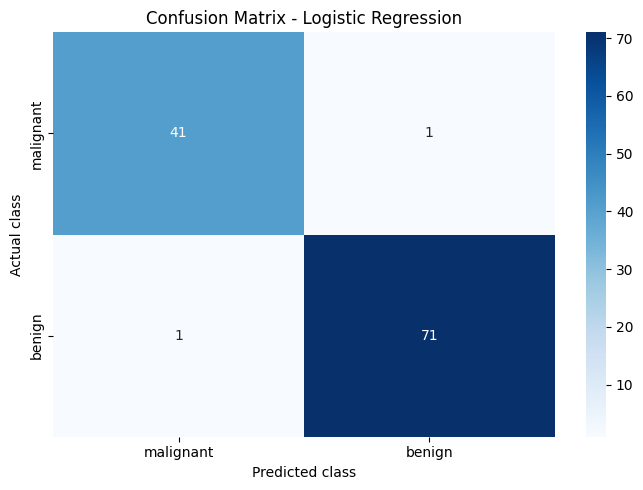

In [4]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=dataset.target_names,
    yticklabels=dataset.target_names
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

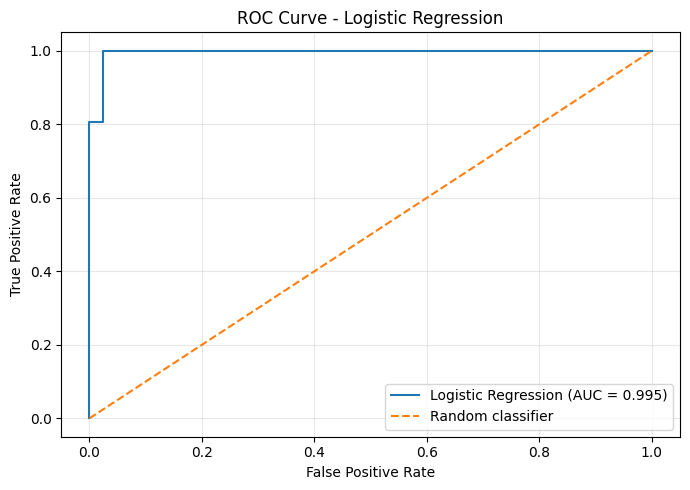

In [5]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=300)
plt.show()

In [6]:
results.to_csv("model_evaluation_metrics.csv", index=False)

with open("model_results.txt", "w") as f:
    f.write("Machine Learning Model Evaluation\n")
    f.write("Model: Logistic Regression\n\n")
    f.write(results.to_string(index=False))
    f.write("\n\n")
    f.write(classification_report(
        y_test, y_pred,
        target_names=dataset.target_names,
        zero_division=0
    ))

print("Saved evaluation metrics and report.")

Saved evaluation metrics and report.
